# JEPX 11/16 ベースライン — チームの更新基準を反映

本Notebookでは、`y_price`（実測値）と `price_tokyo_lag1d`（前日の同時刻の価格）を比較する。元の `split` を変更せず、チームの9〜10月の検証基準に合わせて新しい `split_updated` を作成する。**機械学習モデルの学習は行わない。**

## 1. 元のCSVを読み込む

ローカル環境：プロジェクトの `data/merged_30min.csv`、またはNotebookと同じ作業フォルダ。Google Colab：指定した場所にファイルが見つからない場合、アップロード画面を表示する。

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error

# ローカル環境およびColabでCSVを探索
filename = 'merged_30min.csv'
cwd = Path.cwd()
options = [cwd / 'data' / filename, cwd / filename, cwd.parent / 'data' / filename, Path('/content') / filename]
csv_path = next((p for p in options if p.is_file()), None)
if csv_path is None:
    try:
        from google.colab import files
    except ImportError as e:
        raise FileNotFoundError(f'{filename} をdata/フォルダに配置してください。現在の作業ディレクトリ： {cwd}') from e
    uploaded = files.upload()
    if filename not in uploaded:
        raise FileNotFoundError(f'{filename}を選択してください。選択されたファイル： {list(uploaded)}')
    csv_path = Path.cwd() / filename

df = pd.read_csv(csv_path, encoding='utf-8-sig')
needed = {'date','slot','split','y_price','price_tokyo_lag1d'}
missing = needed - set(df.columns)
if missing:
    raise ValueError(f'必須列が不足しています： {sorted(missing)}')
print('CSV:', csv_path)
print('データのサイズ：', df.shape)
print('従来のsplit別の行数：', df['split'].value_counts().to_dict())

Saving merged_30min.csv to merged_30min.csv
CSV: /content/merged_30min.csv
データのサイズ： (45312, 73)
従来のsplit別の行数： {'train': 18960, 'test': 17520, 'valid': 8832}


## 2. チームの最新の期間区分

**元の `split` は保持**し、最新の区分を `split_updated` に設定する。時系列の train / valid / test を無作為に混合しない。

In [2]:
df['date'] = pd.to_datetime(df['date'], errors='raise')
if df.duplicated(['date', 'slot']).any():
    raise ValueError('date+slotに重複があります。')

df['split_updated'] = np.select(
    [df['date'] <= pd.Timestamp('2025-08-31'),
     df['date'].between('2025-09-01','2025-10-31'),
     df['date'] >= pd.Timestamp('2025-11-01')],
    ['train', 'valid', 'test'], default='unknown')
print('最新のsplit別の行数：', df['split_updated'].value_counts().to_dict())
assert (df['split_updated'] != 'unknown').all()
assert df['date'].min() == pd.Timestamp('2024-04-01')
assert df['date'].max() == pd.Timestamp('2026-10-31')

最新のsplit別の行数： {'train': 24864, 'test': 17520, 'valid': 2928}


## 3. 最新基準でMAEを算出

定義：`MAE = |実測値 − 予測値| の平均`。scikit-learnの公式関数による結果と手計算が一致することを確認する。

In [3]:
records = []
for split_name in ('valid','test'):
    part = df.loc[df['split_updated'].eq(split_name)].copy()
    for col in ('y_price','price_tokyo_lag1d'):
        part[col] = pd.to_numeric(part[col], errors='coerce')
    usable = part.replace([np.inf,-np.inf], np.nan).dropna(subset=['y_price','price_tokyo_lag1d'])
    if usable.empty:
        raise ValueError(f'{split_name}: 評価可能な行がありません。')
    mae = mean_absolute_error(usable['y_price'], usable['price_tokyo_lag1d'])
    manual_mae = (usable['y_price']-usable['price_tokyo_lag1d']).abs().mean()
    assert abs(mae-manual_mae) < 1e-10
    records.append(dict(split=split_name, date_start=usable.date.min().date().isoformat(),
                        date_end=usable.date.max().date().isoformat(), n_rows=len(usable),
                        excluded_rows=len(part)-len(usable), baseline_mae=mae))
results = pd.DataFrame(records)
print(results.to_string(index=False))
print('チーム基準の検証MAE：', f"{results.loc[results.split.eq('valid'),'baseline_mae'].iloc[0]:.6f}")
print('Test MAE:', f"{results.loc[results.split.eq('test'),'baseline_mae'].iloc[0]:.6f}")
assert len(df)==45312 and len(df.columns)==74
assert results.loc[results.split.eq('valid'),'n_rows'].iloc[0]==2928
assert results.loc[results.split.eq('test'),'n_rows'].iloc[0]==17520

split date_start   date_end  n_rows  excluded_rows  baseline_mae
valid 2025-09-01 2025-10-31    2928              0      1.832363
 test 2025-11-01 2026-10-31   17520              0      3.273166
チーム基準の検証MAE： 1.832363
Test MAE: 3.273166


## 4. 結果の保存と解釈

`results` フォルダに新しいCSVを保存する。Colabで実行する場合は `/content/results` に出力されることがあるため、必要に応じてダウンロードする。

In [4]:
out_dir = Path.cwd() / 'results'
out_dir.mkdir(exist_ok=True, parents=True)
out_file = out_dir / 'baseline_mae_updated.csv'
results.to_csv(out_file, index=False, encoding='utf-8-sig', float_format='%.15f')
print('保存完了：', out_file)

保存完了： /content/results/baseline_mae_updated.csv


## 5. 結果の解釈

- 当初の課題で使用した従来の検証期間（2025年5〜10月）のMAE **1.894855** は正しい。
- チームで統一した最新の検証期間（2025年9〜10月）のMAEは **1.832363** である。
- テスト期間（2025年11月〜2026年10月）のMAEは **3.273166** で、従来と変わらない。
- LightGBMのA/Bモデルは、**共通の検証期間（2025年9〜10月）**で比較する。学習期間が異なっていても比較は可能である。
- テストデータの結果を基にモデルを選択したり、ハイパーパラメータを調整したりしない。

従来の検証期間の計算自体は正しいが、モデル比較では共通の検証期間（2025年9〜10月）のMAE **1.832363** を使用する。テストMAEは **3.273166** である。

## 6. チーム共有用の回帰ベースライン可視化（11/16）

以下のグラフは**モデル学習前のベースライン**だけを評価する。分類モデルのPR曲線や特徴量重要度とは異なる指標である。検証期間は**2025年9〜10月**、テスト期間は**2025年11月〜2026年10月**とし、テスト結果はモデル調整に利用しない。

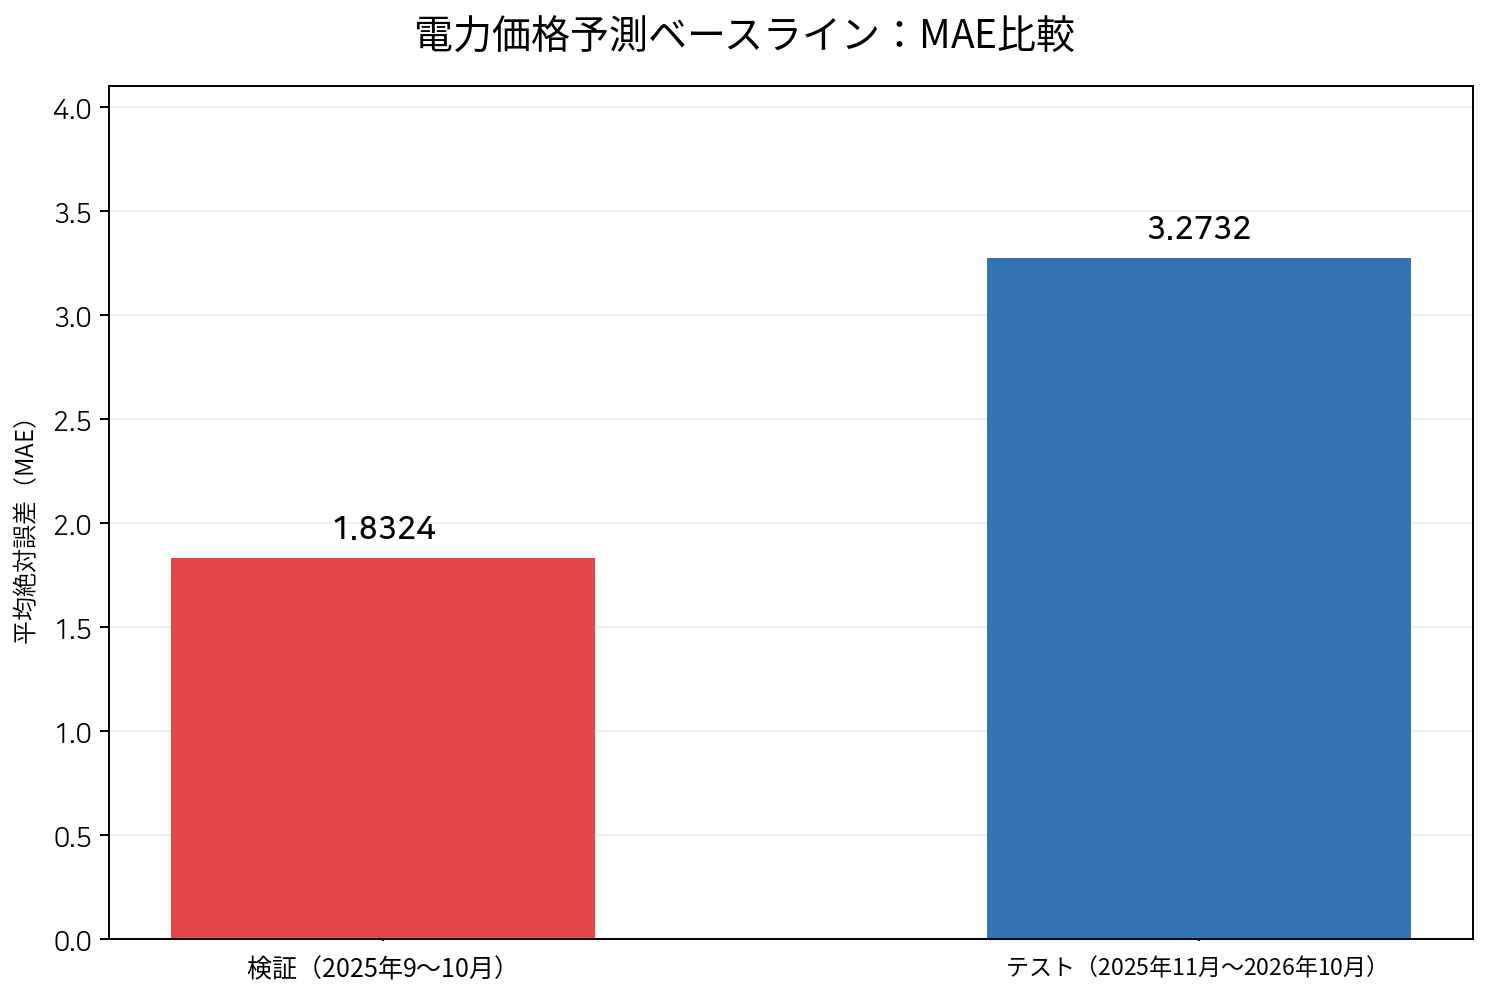

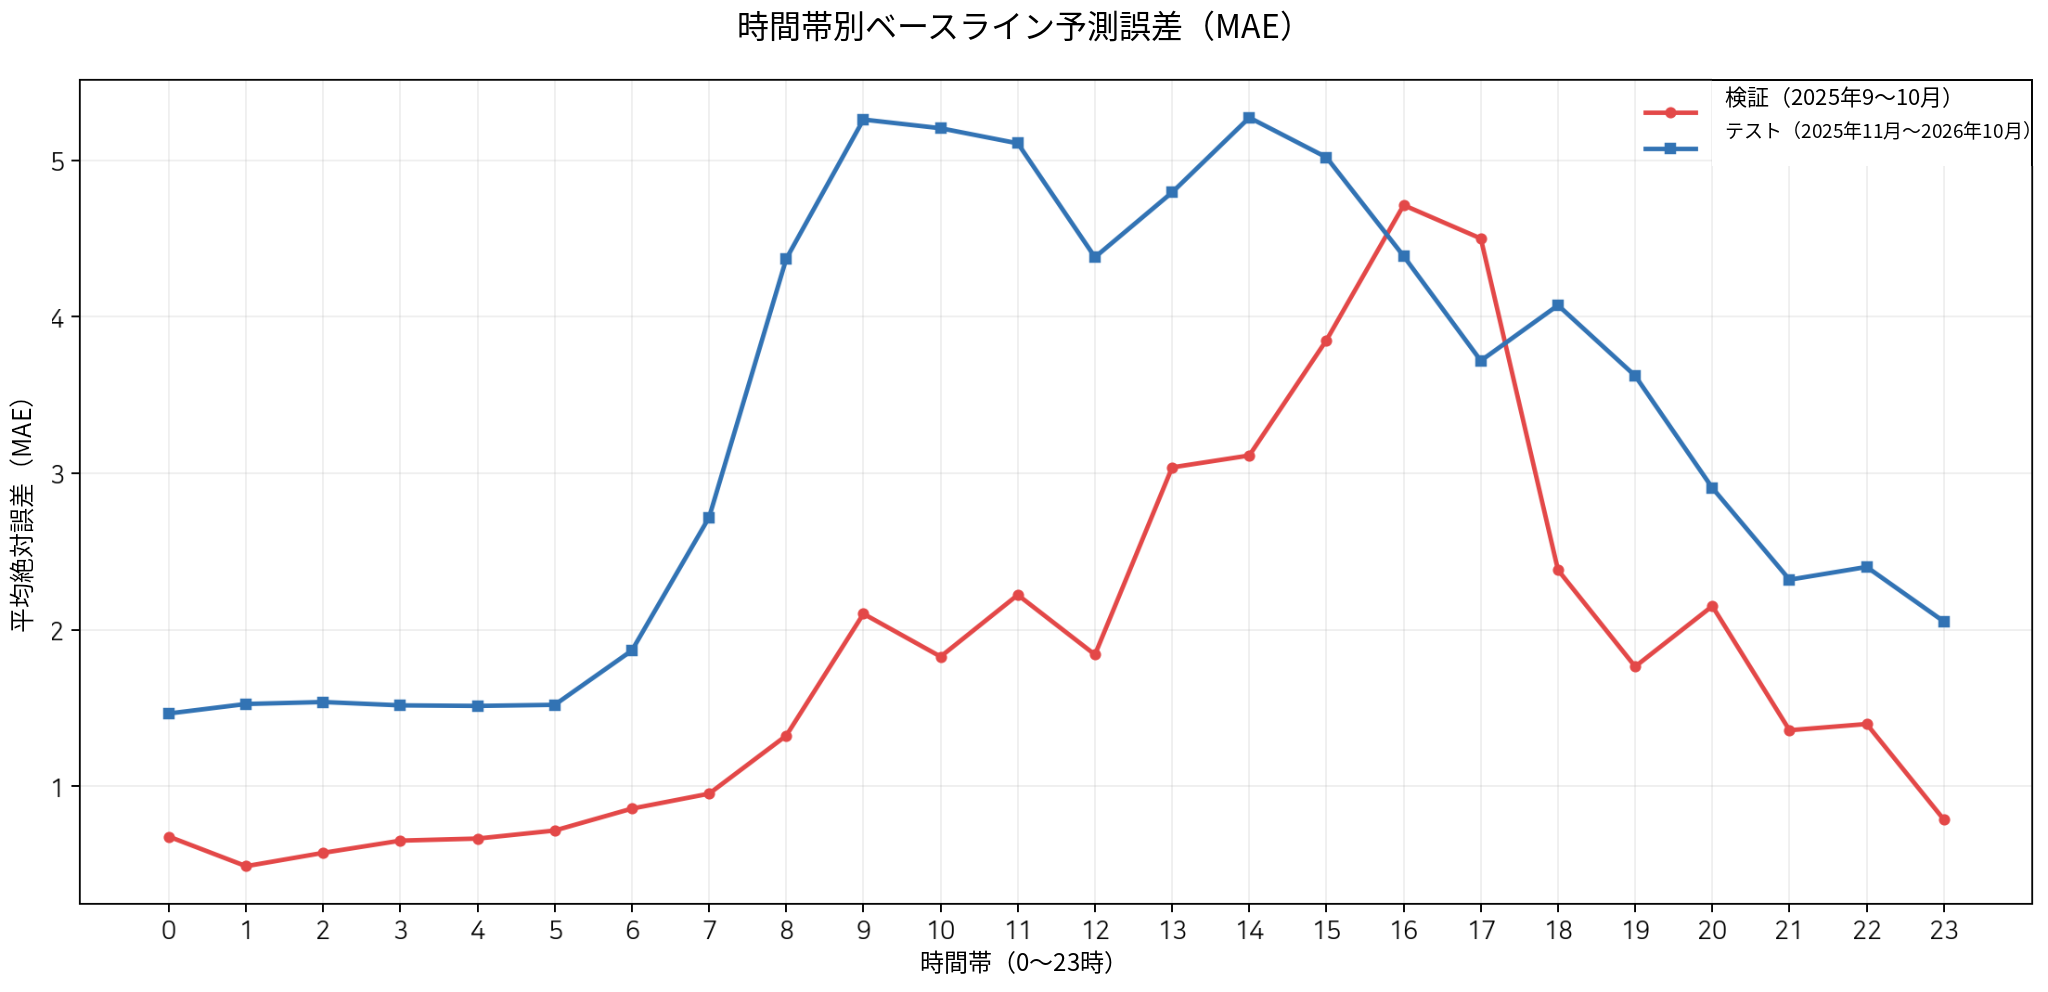

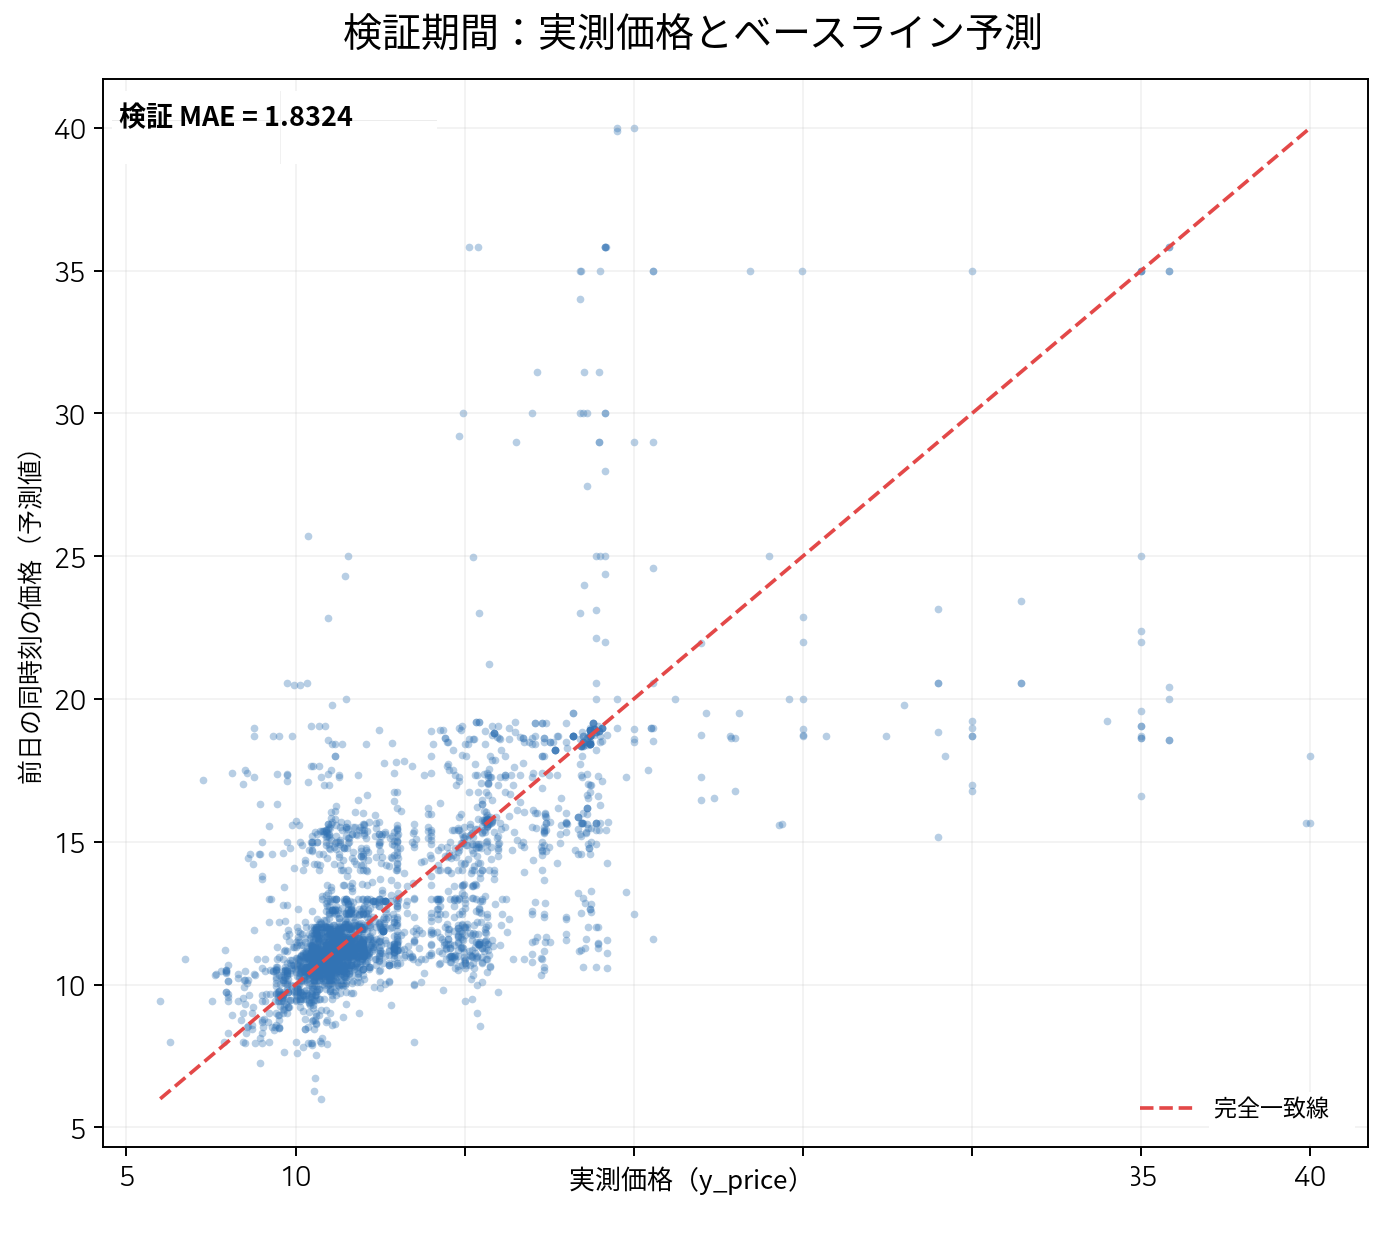

グラフ3枚の保存先： /content/regression_charts


In [5]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 日本語のグラフ見出しを表示するため、日本語フォントを設定（フォントがない場合は警告）
# 実行環境で利用可能な日本語フォントを優先する。
for jp_font in ('Noto Sans CJK JP', 'Noto Sans JP', 'IPAexGothic', 'IPAGothic', 'Yu Gothic', 'Meiryo', 'Hiragino Sans'):
    if jp_font in {f.name for f in fm.fontManager.ttflist}:
        plt.rcParams['font.family'] = jp_font
        break
else:
    print('注意：日本語フォントが見つかりません。文字化けする場合は日本語フォントをインストールしてください。')

plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

plot_dir = Path.cwd() / 'regression_charts'
plot_dir.mkdir(exist_ok=True, parents=True)

plot_df = df.loc[df['split_updated'].isin(['valid', 'test'])].copy()
plot_df['y_price'] = pd.to_numeric(plot_df['y_price'], errors='coerce')
plot_df['price_tokyo_lag1d'] = pd.to_numeric(plot_df['price_tokyo_lag1d'], errors='coerce')
plot_df = plot_df.replace([np.inf,-np.inf], np.nan).dropna(subset=['y_price','price_tokyo_lag1d'])
plot_df['abs_error'] = (plot_df['y_price'] - plot_df['price_tokyo_lag1d']).abs()
valid = plot_df[plot_df['split_updated'] == 'valid']
test = plot_df[plot_df['split_updated'] == 'test']
assert len(valid) == 2928 and len(test) == 17520

# 1：期間別ベースラインMAE
fig, ax = plt.subplots(figsize=(8,5))
vals = [valid['abs_error'].mean(), test['abs_error'].mean()]
labels = ['検証（2025年9〜10月）', 'テスト（2025年11月〜2026年10月）']
bars = ax.bar(labels, vals, color=['tab:red','tab:blue'],width=.55)
for b in bars:
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+.08, f'{b.get_height():.4f}', ha='center')
ax.set(title='期間別ベースラインMAEの比較', ylabel='平均絶対誤差（MAE）', ylim=(0,4.2))
ax.grid(axis='y', alpha=.2)
fig.tight_layout()
fig.savefig(plot_dir/'regression_baseline_mae.png',dpi=160)
plt.show()

# 2：時間帯別の誤差
fig, ax = plt.subplots(figsize=(11,5))
for label,part in [('検証',valid),('テスト',test)]:
    by_hour = part.groupby('hour')['abs_error'].mean()
    ax.plot(by_hour.index,by_hour.values,marker='o',markersize=3,label=label)
ax.set(title='時間帯別のベースライン予測誤差（MAE）',xlabel='時間帯（0〜23時）',ylabel='平均絶対誤差（MAE）',xticks=range(24))
ax.legend(); ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(plot_dir/'regression_hourly_mae.png',dpi=160)
plt.show()

# 3：実測値と予測値（検証期間）
fig, ax = plt.subplots(figsize=(7,6))
ax.scatter(valid['y_price'],valid['price_tokyo_lag1d'],s=8,alpha=.3)
lo = min(valid['y_price'].min(),valid['price_tokyo_lag1d'].min())
hi = max(valid['y_price'].max(),valid['price_tokyo_lag1d'].max())
ax.plot([lo,hi],[lo,hi],'--',color='tab:red',label='完全一致線')
ax.set(title='検証期間：実測価格と前日の同時刻価格',xlabel='実測価格（y_price）',ylabel='前日の同時刻の価格（予測値）')
ax.legend(); ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(plot_dir/'regression_actual_vs_pred.png',dpi=160)
plt.show()
print('グラフ3枚の保存先：',plot_dir)


### 結果の解釈

- **MAEの比較：** 検証期間は1.832363、テスト期間は3.273166。対象期間が異なるため、性能が変化したと単純には断定できない。
- **時間帯別の誤差：** 前日の価格をそのまま予測値とする方法で、どの時間帯に誤差が大きいかを確認する。
- **実測値と予測値：** 対角線から離れるほど予測誤差が大きい。
- **注意：** 回帰モデル自体はまだ学習していないため、特徴量重要度や学習済み回帰モデルの性能改善は、この可視化の対象外とする。

In [6]:
import shutil
from google.colab import files

# グラフ3枚をZIPファイルにまとめる
shutil.make_archive(
    "/content/JEPX_回帰ベースライン図",
    "zip",
    "/content/regression_charts"
)

# PCへダウンロード
files.download("/content/JEPX_回帰ベースライン図.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>